## 1. Configuração da GPU

In [1]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA disponivel:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria da GPU (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("Nenhuma GPU CUDA disponivel.")


PyTorch: 2.14.1+cu130
CUDA disponivel: True
GPU: Tesla T4
Memoria da GPU (GB): 14.56


## 2. Acesso ao repositório GitHub

In [4]:

from pathlib import Path
import subprocess

# Pedir o endereco do repositorio
url = input("Cole o link HTTPS do AgroSeletivo no GitHub: ").strip()

# Definir onde o projeto ficara no Colab
pasta = Path("/content/AgroSeletivo")

# Clonar o repositorio se ainda nao existir
if not pasta.exists():
    subprocess.run(
        ["git", "clone", url, str(pasta)],
        check=True
    )

# Mostrar os codigos encontrados
print("\nArquivos Python do AgroSeletivo:")

for arquivo in sorted((pasta / "src").glob("*.py")):
    print("-", arquivo.name)

print("\nRepositorio acessado com sucesso!")


Cole o link HTTPS do AgroSeletivo no GitHub: https://github.com/IzabelleImamura/AgroSeletivo.git

Arquivos Python do AgroSeletivo:
- analisar_distribuicao.py
- analisar_recortes.py
- dataset_agroseletivo.py
- modelo_agroseletivo.py
- testar_rotulos.py
- testar_treinamento.py
- verificar_amostra.py
- verificar_dataset.py
- visualizar_amostra.py

Repositorio acessado com sucesso!


## 3. Configuração das bibliotecas

Nesta etapa, instalamos e verificamos as bibliotecas necessárias para executar o modelo de segmentação semântica AgroSeletivo.

- **PyTorch:** criação, treinamento e execução da rede neural.
- **Segmentation Models PyTorch:** implementação da arquitetura U-Net.
- **CUDA:** permite utilizar a GPU NVIDIA para acelerar o processamento.

In [5]:
!pip install -q segmentation-models-pytorch

In [6]:
import torch
import segmentation_models_pytorch as smp

print("PyTorch:", torch.__version__)
print("Biblioteca de segmentacao:", smp.__version__)
print("GPU disponivel:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Bibliotecas carregadas com sucesso!")

PyTorch: 2.14.1+cu130
Biblioteca de segmentacao: 0.6.0
GPU disponivel: True
GPU: Tesla T4
Bibliotecas carregadas com sucesso!


## 4. Preparação dos dados — PhenoBench

Nesta etapa, configuramos o acesso ao Google Drive para armazenar os dados e resultados do AgroSeletivo.

O dataset PhenoBench contém fotografias de lavouras e máscaras utilizadas para ensinar a rede neural a distinguir solo, plantas cultivadas e plantas daninhas.

**Objetivos:**
- Acessar os dados necessários ao treinamento.
- Preservar a separação entre treinamento e validação.
- Armazenar os modelos e resultados fora do ambiente temporário do Colab.

In [7]:

from google.colab import drive
from pathlib import Path

# Conectar o Google Drive
drive.mount("/content/drive")

# Pasta principal do projeto no Google Drive
PASTA_DRIVE = Path("/content/drive/MyDrive/AgroSeletivo")

# Criar pastas para organizar os arquivos
for nome in ["dados", "modelos", "resultados"]:
    (PASTA_DRIVE / nome).mkdir(
        parents=True,
        exist_ok=True
    )

print("Google Drive conectado com sucesso!")
print("\nPastas do AgroSeletivo:")

for pasta in sorted(PASTA_DRIVE.iterdir()):
    if pasta.is_dir():
        print("-", pasta.name)


Mounted at /content/drive
Google Drive conectado com sucesso!

Pastas do AgroSeletivo:
- dados
- modelos
- resultados



### 4.1 — Carregamento do dataset piloto

Nesta etapa, carregamos um subconjunto do PhenoBench para realizar o primeiro experimento de treinamento do AgroSeletivo.

**Dados utilizados:**
- 200 fotografias e máscaras para treinamento.
- 50 fotografias e máscaras para validação.
- Imagens originais de 1024 × 1024 pixels.
- Máscaras de segmentação semântica.

As imagens foram selecionadas com semente aleatória 42, preservando os conjuntos originais de treinamento e validação.

O pacote está armazenado no Google Drive e será extraído no ambiente temporário do Colab para facilitar o acesso durante o treinamento.

**Objetivo da verificação:** confirmar que todas as fotografias possuem suas máscaras correspondentes e que os conjuntos estão organizados corretamente.


In [8]:

from pathlib import Path
from zipfile import ZipFile
import shutil

# Caminho do arquivo ZIP no Google Drive
arquivo_zip = Path(
    "/content/drive/MyDrive/AgroSeletivo/dados/"
    "AgroSeletivo_dados_piloto.zip"
)

# Pasta do dataset dentro do projeto clonado
pasta_dataset = Path(
    "/content/AgroSeletivo/dados/phenobench"
)

# Verificar se o ZIP existe
if not arquivo_zip.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {arquivo_zip}"
    )

# Copiar o ZIP para o armazenamento local do Colab
zip_local = Path("/content/AgroSeletivo_dados_piloto.zip")

shutil.copy2(arquivo_zip, zip_local)

# Extrair as imagens e mascaras
pasta_dataset.mkdir(parents=True, exist_ok=True)

with ZipFile(zip_local, "r") as pacote:
    pacote.extractall(pasta_dataset)

print("AGROSELETIVO - VERIFICACAO DOS DADOS")

# Verificar treinamento e validacao
for conjunto, esperado in [("train", 200), ("val", 50)]:

    pasta = pasta_dataset / conjunto

    imagens = sorted((pasta / "imagens").glob("*.png"))
    mascaras = sorted((pasta / "mascaras").glob("*.png"))

    nomes_imagens = {a.name for a in imagens}
    nomes_mascaras = {a.name for a in mascaras}

    print(f"\nCONJUNTO: {conjunto.upper()}")
    print("Fotografias:", len(imagens))
    print("Mascaras:", len(mascaras))
    print("Correspondencia:", nomes_imagens == nomes_mascaras)

    if (
        len(imagens) != esperado
        or len(mascaras) != esperado
        or nomes_imagens != nomes_mascaras
    ):
        raise ValueError(
            f"Problema encontrado no conjunto {conjunto}"
        )

print("\nDataset piloto preparado com sucesso!")


AGROSELETIVO - VERIFICACAO DOS DADOS

CONJUNTO: TRAIN
Fotografias: 200
Mascaras: 200
Correspondencia: True

CONJUNTO: VAL
Fotografias: 50
Mascaras: 50
Correspondencia: True

Dataset piloto preparado com sucesso!



### 4.2 — Teste de carregamento dos dados com PyTorch

Nesta etapa, verificamos se o componente `PhenoBenchDataset` consegue carregar as fotografias e máscaras do conjunto piloto.

O código realiza as seguintes operações:

- Carrega as imagens e máscaras do PhenoBench.
- Converte as cinco classes originais em três categorias: solo, cultura e plantas daninhas.
- Prepara recortes de 512 × 512 pixels.
- Normaliza as fotografias para o encoder pré-treinado.
- Organiza os dados em lotes utilizando o `DataLoader` do PyTorch.

**Objetivo:** confirmar que os dados estão no formato esperado pela U-Net antes de iniciar o treinamento.


In [9]:

import sys
import torch

from pathlib import Path
from torch.utils.data import DataLoader


# 1. Localizar os codigos do AgroSeletivo
PASTA_SRC = Path("/content/AgroSeletivo/src")

if str(PASTA_SRC) not in sys.path:
    sys.path.insert(0, str(PASTA_SRC))

from dataset_agroseletivo import PhenoBenchDataset


# 2. Carregar os conjuntos
treino = PhenoBenchDataset("train")
validacao = PhenoBenchDataset("val")

print("AGROSELETIVO - TESTE DOS DADOS NO COLAB")

print("\nCONJUNTOS")
print("Fotografias de treino:", len(treino.arquivos))
print("Fotografias de validacao:", len(validacao.arquivos))
print("Amostras de treino:", len(treino))
print("Recortes de validacao:", len(validacao))


# 3. Criar um carregador de dados
carregador = DataLoader(
    treino,
    batch_size=2,
    shuffle=True,
    num_workers=0
)


# 4. Carregar o primeiro lote
imagens, mascaras = next(iter(carregador))

print("\nLOTE CARREGADO")
print("Formato das imagens:", imagens.shape)
print("Formato das mascaras:", mascaras.shape)
print("Tipo das imagens:", imagens.dtype)
print("Tipo das mascaras:", mascaras.dtype)

print(
    "Classes encontradas:",
    torch.unique(mascaras).tolist()
)


# 5. Verificar se os formatos estao corretos
assert len(treino.arquivos) == 200
assert len(validacao.arquivos) == 50

assert imagens.shape == (2, 3, 512, 512)
assert mascaras.shape == (2, 512, 512)

assert torch.isfinite(imagens).all().item()

assert torch.all(
    (mascaras >= 0) & (mascaras <= 2)
).item()

print("\nDados preparados corretamente!")


AGROSELETIVO - TESTE DOS DADOS NO COLAB

CONJUNTOS
Fotografias de treino: 200
Fotografias de validacao: 50
Amostras de treino: 200
Recortes de validacao: 200

LOTE CARREGADO
Formato das imagens: torch.Size([2, 3, 512, 512])
Formato das mascaras: torch.Size([2, 512, 512])
Tipo das imagens: torch.float32
Tipo das mascaras: torch.int64
Classes encontradas: [0, 1, 2]

Dados preparados corretamente!



### 4.3 — Carregamento do conjunto completo de treinamento

Nesta etapa, substituímos o conjunto piloto de 200 fotografias pelo conjunto completo de treinamento do PhenoBench.

**Dados utilizados:**
- 1.407 fotografias de treinamento.
- 1.407 máscaras de segmentação correspondentes.
- Imagens originais de 1024 × 1024 pixels.
- Máscaras com as categorias de solo, cultura e plantas daninhas.

O arquivo ZIP está armazenado no Google Drive e será extraído para o armazenamento temporário do Colab.

**Objetivo:** aumentar a quantidade e a diversidade de exemplos utilizados para treinar a U-Net.

O conjunto de validação piloto permanecerá separado e não será utilizado para atualizar os pesos da rede neural.

Posteriormente, ampliaremos a validação e planejaremos uma avaliação final independente.


In [17]:

from pathlib import Path
from zipfile import ZipFile
import shutil

# ==========================================
# 1. DEFINIR OS CAMINHOS
# ==========================================

arquivo_zip = Path(
    "/content/drive/MyDrive/AgroSeletivo/dados/"
    "AgroSeletivo_treino_completo.zip"
)

zip_local = Path(
    "/content/AgroSeletivo_treino_completo.zip"
)

pasta_dataset = Path(
    "/content/AgroSeletivo/dados/phenobench"
)

print("AGROSELETIVO - TREINAMENTO COMPLETO")


# ==========================================
# 2. CONFERIR O ARQUIVO
# ==========================================

if not arquivo_zip.is_file():
    raise FileNotFoundError(
        f"ZIP nao encontrado: {arquivo_zip}"
    )

print("\nArquivo encontrado no Google Drive!")


# ==========================================
# 3. COPIAR E EXTRAIR OS DADOS
# ==========================================

# Conferir o espaco disponivel no Colab
with ZipFile(arquivo_zip, "r") as pacote:
    arquivos_zip = pacote.infolist()
    tamanho_extraido = sum(
        arquivo.file_size for arquivo in arquivos_zip
    )

    nomes = [arquivo.filename for arquivo in arquivos_zip]

    if len(nomes) != 2814:
        raise ValueError("Quantidade inesperada no ZIP!")

    if not all(
        nome.startswith("train/")
        and len(Path(nome).parts) == 3
        and Path(nome).parts[1] in ("imagens", "mascaras")
        and nome.endswith(".png")
        for nome in nomes
    ):
        raise ValueError("Estrutura inesperada no ZIP!")

espaco_livre = shutil.disk_usage("/content").free
espaco_necessario = (
    arquivo_zip.stat().st_size + tamanho_extraido
)

if espaco_livre < espaco_necessario:
    raise RuntimeError(
        "Espaco local insuficiente para copiar e extrair o ZIP."
    )

print("Copiando o pacote para o Colab...")

shutil.copy2(arquivo_zip, zip_local)

print("Extraindo fotografias e mascaras...")

try:
    pasta_dataset.mkdir(parents=True, exist_ok=True)

    with ZipFile(zip_local, "r") as pacote:
        pacote.extractall(pasta_dataset)
finally:
    # Remover a copia temporaria do ZIP
    zip_local.unlink(missing_ok=True)

print("Extracao finalizada!")


# ==========================================
# 4. VERIFICAR OS ARQUIVOS
# ==========================================

pasta_treino = pasta_dataset / "train"

imagens = sorted(
    (pasta_treino / "imagens").glob("*.png")
)

mascaras = sorted(
    (pasta_treino / "mascaras").glob("*.png")
)

nomes_imagens = {a.name for a in imagens}
nomes_mascaras = {a.name for a in mascaras}

print("\nVERIFICACAO")

print("Fotografias:", len(imagens))
print("Mascaras:", len(mascaras))
print("Correspondencia:", nomes_imagens == nomes_mascaras)

assert len(imagens) == 1407
assert len(mascaras) == 1407
assert nomes_imagens == nomes_mascaras

# Confirmar que a validacao piloto continua separada
imagens_val = list(
    (pasta_dataset / "val" / "imagens").glob("*.png")
)

print("Fotografias de validacao:", len(imagens_val))

assert len(imagens_val) == 50

print("\nDataset completo preparado com sucesso!")


AGROSELETIVO - TREINAMENTO COMPLETO

Arquivo encontrado no Google Drive!
Copiando o pacote para o Colab...
Extraindo fotografias e mascaras...
Extracao finalizada!

VERIFICACAO
Fotografias: 1407
Mascaras: 1407
Correspondencia: True
Fotografias de validacao: 50

Dataset completo preparado com sucesso!



## 5. Configuração do modelo de Inteligência Artificial

Nesta etapa, utilizamos uma rede neural U-Net com encoder MobileNetV2 para realizar segmentação semântica das fotografias agrícolas.

**Arquitetura utilizada:**
- **U-Net:** responsável pela segmentação das imagens.
- **MobileNetV2:** extrai características visuais das fotografias.
- **Pesos pré-treinados em ImageNet:** fornecem conhecimentos visuais iniciais ao encoder.
- **Três classes de saída:** solo, planta cultivada e planta daninha.

O modelo será executado na GPU NVIDIA Tesla T4, disponibilizada pelo Google Colab.

### 5.1 — Inicialização e teste da U-Net

Nesta etapa, carregamos a arquitetura, transferimos seus parâmetros para a GPU e realizamos uma previsão experimental com uma fotografia de validação.

**Objetivo:** verificar o funcionamento técnico da rede antes do treinamento.

**Importante:** os pesos iniciais ainda não foram ajustados para identificar plantas daninhas. Portanto, as previsões geradas neste teste não representam o desempenho final do AgroSeletivo.


In [10]:

import sys
from pathlib import Path

import torch

# 1. Localizar os codigos do projeto
PASTA_SRC = Path("/content/AgroSeletivo/src")

if str(PASTA_SRC) not in sys.path:
    sys.path.insert(0, str(PASTA_SRC))

from dataset_agroseletivo import PhenoBenchDataset
from modelo_agroseletivo import criar_modelo


print("AGROSELETIVO - TESTE DA U-NET NA GPU")

# 2. Verificar a disponibilidade da GPU
if not torch.cuda.is_available():
    raise RuntimeError("GPU CUDA nao disponivel!")

dispositivo = torch.device("cuda")

print("\nDISPOSITIVO")
print("GPU:", torch.cuda.get_device_name(0))


# 3. Criar nossa U-Net
print("\nCriando a U-Net com MobileNetV2...")

modelo = criar_modelo()

# Transferir a rede para a GPU
modelo = modelo.to(dispositivo)

# Ativar modo de avaliacao
modelo.eval()

parametros = sum(
    p.numel() for p in modelo.parameters()
)

print("Parametros do modelo:", parametros)


# 4. Carregar uma fotografia de validacao
dataset_val = PhenoBenchDataset("val")

imagem, mascara = dataset_val[0]

# Adicionar dimensao de lote e enviar para GPU
entrada = imagem.unsqueeze(0).to(dispositivo)

print("\nDADOS")
print("Entrada:", entrada.shape)
print("Dispositivo:", entrada.device)


# 5. Executar a rede neural
with torch.inference_mode():

    saida = modelo(entrada)

    # Selecionar a classe de maior valor em cada pixel
    previsao = torch.argmax(saida, dim=1)


# 6. Verificar os resultados
print("\nRESULTADO")

print("Saida da rede:", saida.shape)
print("Mascara prevista:", previsao.shape)

print(
    "Classes previstas:",
    torch.unique(previsao).tolist()
)

print(
    "Valores numericos validos:",
    torch.isfinite(saida).all().item()
)

assert saida.shape == (1, 3, 512, 512)
assert torch.isfinite(saida).all().item()

print("\nU-Net executada com sucesso na GPU!")
print("ATENCAO: o modelo ainda nao foi treinado.")


AGROSELETIVO - TESTE DA U-NET NA GPU

DISPOSITIVO
GPU: Tesla T4

Criando a U-Net com MobileNetV2...


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Parametros do modelo: 6629235

DADOS
Entrada: torch.Size([1, 3, 512, 512])
Dispositivo: cuda:0

RESULTADO
Saida da rede: torch.Size([1, 3, 512, 512])
Mascara prevista: torch.Size([1, 512, 512])
Classes previstas: [0, 1, 2]
Valores numericos validos: True

U-Net executada com sucesso na GPU!
ATENCAO: o modelo ainda nao foi treinado.



## 6. Treinamento da rede neural

Nesta etapa, iniciamos o treinamento supervisionado da U-Net com encoder MobileNetV2 utilizando o dataset PhenoBench.

A rede recebe fotografias de lavouras e aprende a produzir máscaras de segmentação com três categorias:

- **Classe 0:** solo/fundo.
- **Classe 1:** planta cultivada.
- **Classe 2:** planta daninha.

### 6.1 — Primeiro experimento: treinamento de referência

O primeiro experimento utiliza 200 fotografias para treinamento e 50 para validação.

**Configurações iniciais:**
- Arquitetura: U-Net com MobileNetV2 pré-treinada em ImageNet.
- Resolução dos recortes: 512 × 512 pixels.
- Função de perda: Cross-Entropy sem pesos de classe.
- Otimizador: AdamW.
- Taxa de aprendizado: 0.0001.
- Batch size: 2.
- Épocas: 1.

**Objetivo:** verificar o funcionamento completo do treinamento e obter resultados iniciais de segmentação.

O desempenho será avaliado com IoU por classe, precisão e recall.

Como as plantas daninhas representam aproximadamente 0,5% dos pixels, posteriormente poderemos comparar esse experimento com técnicas que consideram o desequilíbrio das classes.

Este é um experimento preliminar, não a avaliação final do AgroSeletivo.


In [11]:

import random
import json
import numpy as np
import torch

from pathlib import Path
from torch.utils.data import DataLoader

from dataset_agroseletivo import PhenoBenchDataset
from modelo_agroseletivo import criar_modelo


# ==========================================
# 1. CONFIGURACOES DO EXPERIMENTO
# ==========================================

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

dispositivo = torch.device("cuda")

EPOCAS = 1
BATCH_SIZE = 2
TAXA_APRENDIZADO = 0.0001

print("AGROSELETIVO - TREINAMENTO PILOTO")


# ==========================================
# 2. CARREGAMENTO DOS DADOS
# ==========================================

treino = PhenoBenchDataset("train")
validacao = PhenoBenchDataset("val")

carregador_treino = DataLoader(
    treino,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

carregador_val = DataLoader(
    validacao,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\nDados preparados!")
print("Lotes de treinamento:", len(carregador_treino))
print("Lotes de validacao:", len(carregador_val))


# ==========================================
# 3. MODELO, PERDA E OTIMIZADOR
# ==========================================

# Criar um modelo novo para este experimento
modelo = criar_modelo().to(dispositivo)

criterio = torch.nn.CrossEntropyLoss()

otimizador = torch.optim.AdamW(
    modelo.parameters(),
    lr=TAXA_APRENDIZADO
)


# ==========================================
# 4. TREINAMENTO
# ==========================================

for epoca in range(EPOCAS):

    modelo.train()

    perda_treino = 0.0

    print(f"\nEPOCA {epoca + 1}/{EPOCAS}")

    for numero, (imagens, mascaras) in enumerate(
        carregador_treino, start=1
    ):

        imagens = imagens.to(dispositivo)
        mascaras = mascaras.to(dispositivo)

        otimizador.zero_grad(set_to_none=True)

        saida = modelo(imagens)

        perda = criterio(saida, mascaras)

        perda.backward()

        otimizador.step()

        perda_treino += perda.item()

        if numero % 25 == 0:
            print(
                f"Lote {numero}/{len(carregador_treino)} "
                f"- Perda: {perda.item():.4f}"
            )

    perda_treino /= len(carregador_treino)


    # ======================================
    # 5. VALIDACAO
    # ======================================

    modelo.eval()

    perda_validacao = 0.0

    matriz_confusao = torch.zeros(
        (3, 3), dtype=torch.int64
    )

    with torch.inference_mode():

        for imagens, mascaras in carregador_val:

            imagens = imagens.to(dispositivo)
            mascaras = mascaras.to(dispositivo)

            saida = modelo(imagens)

            perda = criterio(saida, mascaras)

            perda_validacao += perda.item()

            previsoes = torch.argmax(saida, dim=1)

            verdade = mascaras.cpu().reshape(-1)
            previsto = previsoes.cpu().reshape(-1)

            indices = verdade * 3 + previsto

            matriz_confusao += torch.bincount(
                indices,
                minlength=9
            ).reshape(3, 3)

    perda_validacao /= len(carregador_val)


    # ======================================
    # 6. CALCULAR AS METRICAS
    # ======================================

    nomes_classes = [
        "Solo",
        "Cultura",
        "Daninhas"
    ]

    matriz = matriz_confusao.numpy()

    metricas = {}

    print("\nRESULTADOS DA EPOCA")

    print(f"Perda treinamento: {perda_treino:.4f}")
    print(f"Perda validacao: {perda_validacao:.4f}")

    for classe, nome in enumerate(nomes_classes):

        vp = matriz[classe, classe]

        total_real = matriz[classe, :].sum()
        total_previsto = matriz[:, classe].sum()

        uniao = (
            total_real + total_previsto - vp
        )

        iou = vp / uniao if uniao > 0 else 0.0

        precisao = (
            vp / total_previsto
            if total_previsto > 0 else 0.0
        )

        recall = (
            vp / total_real
            if total_real > 0 else 0.0
        )

        metricas[nome] = {
            "iou": float(iou),
            "precisao": float(precisao),
            "recall": float(recall)
        }

        print(
            f"{nome}: "
            f"IoU={iou:.4f}, "
            f"Precisao={precisao:.4f}, "
            f"Recall={recall:.4f}"
        )


# ==========================================
# 7. SALVAR OS RESULTADOS
# ==========================================

pasta_drive = Path(
    "/content/drive/MyDrive/AgroSeletivo"
)

pasta_modelos = pasta_drive / "modelos"
pasta_resultados = pasta_drive / "resultados"

pasta_modelos.mkdir(parents=True, exist_ok=True)
pasta_resultados.mkdir(parents=True, exist_ok=True)

caminho_modelo = (
    pasta_modelos / "unet_piloto_epoca1.pt"
)

caminho_metricas = (
    pasta_resultados / "metricas_piloto_epoca1.json"
)

torch.save(
    {
        "epoca": EPOCAS,
        "modelo": modelo.state_dict(),
        "otimizador": otimizador.state_dict(),
        "perda_treino": perda_treino,
        "perda_validacao": perda_validacao,
    },
    caminho_modelo
)

with open(caminho_metricas, "w") as arquivo:
    json.dump(
        {
            "experimento": "piloto_epoca1",
            "epocas": EPOCAS,
            "perda_treino": perda_treino,
            "perda_validacao": perda_validacao,
            "metricas": metricas,
            "matriz_confusao": matriz.tolist()
        },
        arquivo,
        indent=4
    )

print("\nTREINAMENTO FINALIZADO!")
print("Modelo salvo em:", caminho_modelo)
print("Metricas salvas em:", caminho_metricas)


AGROSELETIVO - TREINAMENTO PILOTO

Dados preparados!
Lotes de treinamento: 100
Lotes de validacao: 100

EPOCA 1/1
Lote 25/100 - Perda: 0.6329
Lote 50/100 - Perda: 0.4701
Lote 75/100 - Perda: 0.4747
Lote 100/100 - Perda: 0.2607

RESULTADOS DA EPOCA
Perda treinamento: 0.5699
Perda validacao: 0.2540
Solo: IoU=0.9703, Precisao=0.9744, Recall=0.9956
Cultura: IoU=0.7294, Precisao=0.9275, Recall=0.7735
Daninhas: IoU=0.0115, Precisao=0.1153, Recall=0.0126

TREINAMENTO FINALIZADO!
Modelo salvo em: /content/drive/MyDrive/AgroSeletivo/modelos/unet_piloto_epoca1.pt
Metricas salvas em: /content/drive/MyDrive/AgroSeletivo/resultados/metricas_piloto_epoca1.json



### 6.2 — Análise visual das previsões

Nesta etapa, avaliamos visualmente o modelo após sua primeira época de treinamento.

Utilizamos uma fotografia do conjunto de validação, que não foi utilizada para atualizar os pesos da rede.

Comparamos três representações:

1. **Fotografia original:** entrada recebida pela rede neural.
2. **Máscara real:** identificação de solo, cultura e plantas daninhas fornecida pelo PhenoBench.
3. **Máscara prevista:** classificação produzida pela U-Net treinada.

**Objetivo:** investigar os erros do modelo, principalmente na identificação das plantas daninhas.

Esta análise é exploratória e não substitui as métricas calculadas no conjunto de validação.


Modelo treinado carregado!
Recorte selecionado: 0


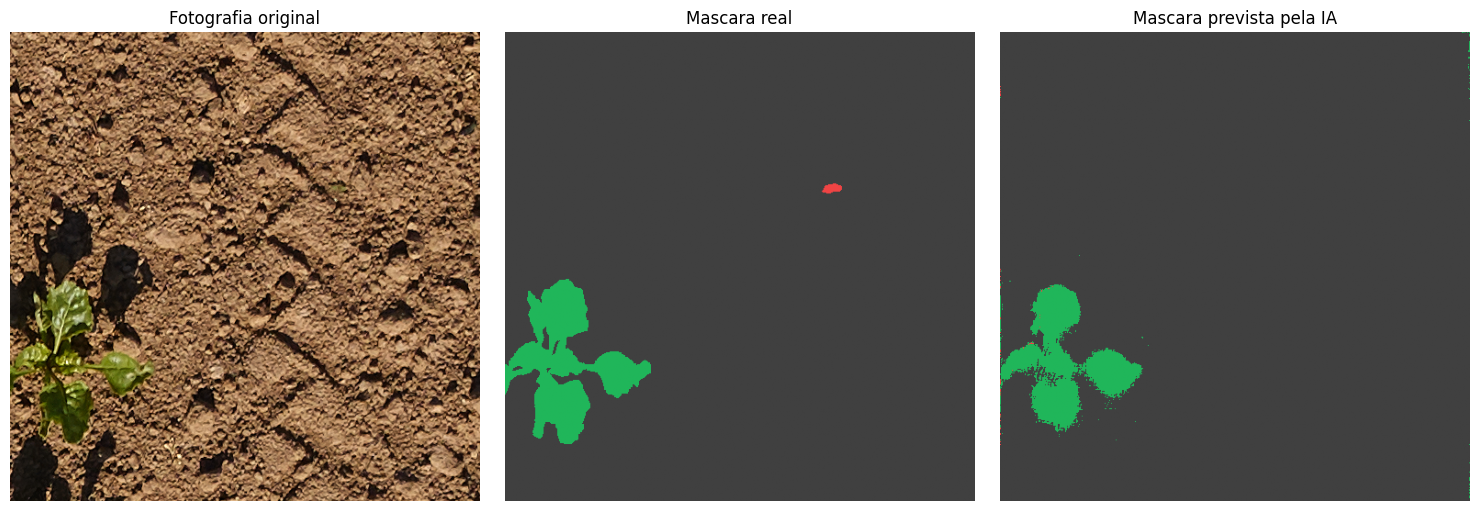


ANALISE DAS PLANTAS DANINHAS
Pixels reais: 166
Pixels previstos: 60
Pixels corretos: 0


In [12]:

import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

from matplotlib.colors import ListedColormap


# ==========================================
# 1. LOCALIZAR OS ARQUIVOS
# ==========================================

pasta_src = "/content/AgroSeletivo/src"

if pasta_src not in sys.path:
    sys.path.insert(0, pasta_src)

from dataset_agroseletivo import PhenoBenchDataset

caminho_modelo = Path(
    "/content/drive/MyDrive/AgroSeletivo/modelos/"
    "unet_piloto_epoca1.pt"
)

dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ==========================================
# 2. CARREGAR O MODELO TREINADO
# ==========================================

rede = smp.Unet(
    encoder_name="mobilenet_v2",
    encoder_weights=None,
    in_channels=3,
    classes=3,
    activation=None
)

checkpoint = torch.load(
    caminho_modelo,
    map_location="cpu",
    weights_only=True
)

rede.load_state_dict(checkpoint["modelo"])
rede = rede.to(dispositivo)
rede.eval()

print("Modelo treinado carregado!")


# ==========================================
# 3. SELECIONAR EXEMPLO DA VALIDACAO
# ==========================================

dataset_val = PhenoBenchDataset("val")

indice_escolhido = 0

# Procurar um recorte com plantas daninhas
for i in range(len(dataset_val)):

    imagem_teste, mascara_teste = dataset_val[i]

    pixels_daninhas = int(
        (mascara_teste == 2).sum()
    )

    if pixels_daninhas >= 100:
        indice_escolhido = i
        break

imagem, mascara_real = dataset_val[indice_escolhido]

print("Recorte selecionado:", indice_escolhido)


# ==========================================
# 4. EXECUTAR A PREVISAO
# ==========================================

entrada = imagem.unsqueeze(0).to(dispositivo)

with torch.inference_mode():
    saida = rede(entrada)
    previsao = torch.argmax(saida, dim=1)

mascara_prevista = previsao[0].cpu().numpy()
mascara_real = mascara_real.numpy()


# ==========================================
# 5. RECUPERAR AS CORES DA FOTOGRAFIA
# ==========================================

media = np.array([0.485, 0.456, 0.406])
desvio = np.array([0.229, 0.224, 0.225])

fotografia = imagem.permute(1, 2, 0).numpy()

fotografia = fotografia * desvio + media
fotografia = np.clip(fotografia, 0, 1)


# ==========================================
# 6. VISUALIZAR OS RESULTADOS
# ==========================================

cores = ListedColormap([
    "#404040",  # Solo
    "#20B65A",  # Cultura
    "#F04444"   # Daninhas
])

fig, eixos = plt.subplots(
    1, 3, figsize=(15, 5)
)

eixos[0].imshow(fotografia)
eixos[0].set_title("Fotografia original")

eixos[1].imshow(
    mascara_real,
    cmap=cores,
    vmin=0,
    vmax=2
)
eixos[1].set_title("Mascara real")

eixos[2].imshow(
    mascara_prevista,
    cmap=cores,
    vmin=0,
    vmax=2
)
eixos[2].set_title("Mascara prevista pela IA")

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()
plt.show()


# ==========================================
# 7. CONFERIR AS PLANTAS DANINHAS
# ==========================================

pixels_reais = np.count_nonzero(
    mascara_real == 2
)

pixels_previstos = np.count_nonzero(
    mascara_prevista == 2
)

pixels_corretos = np.count_nonzero(
    (mascara_real == 2) &
    (mascara_prevista == 2)
)

print("\nANALISE DAS PLANTAS DANINHAS")
print("Pixels reais:", pixels_reais)
print("Pixels previstos:", pixels_previstos)
print("Pixels corretos:", pixels_corretos)



### 6.3 — Análise dos erros por classe

Nesta etapa, analisamos a matriz de confusão produzida durante a validação da primeira época de treinamento.

A matriz de confusão permite identificar quais categorias a rede neural está confundindo.

Nosso principal objetivo é verificar como os pixels reais de plantas daninhas foram classificados:

- Como solo.
- Como planta cultivada.
- Corretamente como planta daninha.

Essa análise ajudará a compreender os erros do primeiro modelo e orientar os próximos experimentos.


In [13]:

import json
import numpy as np
from pathlib import Path


# ==========================================
# 1. CARREGAR AS METRICAS SALVAS
# ==========================================

caminho = Path(
    "/content/drive/MyDrive/AgroSeletivo/resultados/"
    "metricas_piloto_epoca1.json"
)

with open(caminho, "r") as arquivo:
    resultados = json.load(arquivo)

matriz = np.array(resultados["matriz_confusao"])

classes = ["Solo", "Cultura", "Daninhas"]

print("AGROSELETIVO - ANALISE DOS ERROS")


# ==========================================
# 2. MOSTRAR A MATRIZ DE CONFUSAO
# ==========================================

print("\nMATRIZ DE CONFUSAO")
print("Linhas: classe real")
print("Colunas: classe prevista\n")

print(f"{'Real':<12} {'Solo':>12} {'Cultura':>12} {'Daninhas':>12}")

for i, nome in enumerate(classes):
    print(
        f"{nome:<12}"
        f"{matriz[i, 0]:>12}"
        f"{matriz[i, 1]:>12}"
        f"{matriz[i, 2]:>12}"
    )


# ==========================================
# 3. ANALISAR AS PLANTAS DANINHAS
# ==========================================

# Linha 2: pixels realmente classificados como daninhas
daninhas_reais = matriz[2]

total = daninhas_reais.sum()

print("\nDESTINO DOS PIXELS REAIS DE DANINHAS")

for i, nome in enumerate(classes):

    quantidade = int(daninhas_reais[i])

    percentual = (
        quantidade / total * 100
        if total > 0 else 0
    )

    print(
        f"Previstos como {nome}: "
        f"{quantidade} pixels ({percentual:.2f}%)"
    )

print("\nAnalise finalizada!")


AGROSELETIVO - ANALISE DOS ERROS

MATRIZ DE CONFUSAO
Linhas: classe real
Colunas: classe prevista

Real                 Solo      Cultura     Daninhas
Solo            47286193      201046        6608
Cultura          1028178     3587810       22163
Daninhas          213721       79330        3751

DESTINO DOS PIXELS REAIS DE DANINHAS
Previstos como Solo: 213721 pixels (72.01%)
Previstos como Cultura: 79330 pixels (26.73%)
Previstos como Daninhas: 3751 pixels (1.26%)

Analise finalizada!



### 6.4 — Continuação do treinamento: épocas 2 a 5

Após a primeira época, a U-Net apresentou boa identificação de solo e resultados iniciais para plantas cultivadas, mas desempenho insuficiente na identificação de plantas daninhas.

A análise da matriz de confusão mostrou que 72,01% dos pixels de plantas daninhas foram classificados como solo e 26,73% como cultura.

**Objetivo deste experimento:** investigar se aumentar a quantidade de épocas melhora a identificação das plantas daninhas, mantendo a arquitetura, a função de perda e os dados do primeiro experimento.

O treinamento continuará a partir dos pesos e do estado do otimizador salvos ao final da época 1.

Serão registradas as métricas de validação de cada época, permitindo acompanhar a evolução do modelo e identificar possíveis sinais de sobreajuste.

Os checkpoints e resultados serão armazenados no Google Drive, sem sobrescrever o experimento inicial.


In [14]:

import sys
import json
import random
from pathlib import Path

import numpy as np
import torch
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader

# ==========================================
# 1. CONFIGURACAO
# ==========================================

sys.path.insert(0, "/content/AgroSeletivo/src")

from dataset_agroseletivo import PhenoBenchDataset

random.seed(43)
np.random.seed(43)
torch.manual_seed(43)
torch.cuda.manual_seed_all(43)

dispositivo = torch.device("cuda")

PASTA_DRIVE = Path("/content/drive/MyDrive/AgroSeletivo")
PASTA_MODELOS = PASTA_DRIVE / "modelos"
PASTA_RESULTADOS = PASTA_DRIVE / "resultados"

EPOCA_FINAL = 5
BATCH_SIZE = 2

print("AGROSELETIVO - CONTINUACAO DO TREINAMENTO")


# ==========================================
# 2. CARREGAR O CHECKPOINT ANTERIOR
# ==========================================

caminho_anterior = (
    PASTA_MODELOS / "unet_piloto_epoca1.pt"
)

checkpoint = torch.load(
    caminho_anterior,
    map_location="cpu",
    weights_only=True
)

modelo = smp.Unet(
    encoder_name="mobilenet_v2",
    encoder_weights=None,
    in_channels=3,
    classes=3,
    activation=None
).to(dispositivo)

modelo.load_state_dict(checkpoint["modelo"])

criterio = torch.nn.CrossEntropyLoss()

otimizador = torch.optim.AdamW(
    modelo.parameters(),
    lr=0.0001
)

otimizador.load_state_dict(checkpoint["otimizador"])

epoca_inicial = int(checkpoint["epoca"]) + 1

assert epoca_inicial == 2

print("Continuando da epoca:", epoca_inicial)


# ==========================================
# 3. PREPARAR OS DADOS
# ==========================================

treino = PhenoBenchDataset("train")
validacao = PhenoBenchDataset("val")

carregador_treino = DataLoader(
    treino,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

carregador_val = DataLoader(
    validacao,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

historico = []


# ==========================================
# 4. TREINAR E VALIDAR CADA EPOCA
# ==========================================

for epoca in range(epoca_inicial, EPOCA_FINAL + 1):

    print(f"\n========== EPOCA {epoca} ==========")

    modelo.train()
    soma_treino = 0.0

    for imagens, mascaras in carregador_treino:

        imagens = imagens.to(dispositivo)
        mascaras = mascaras.to(dispositivo)

        otimizador.zero_grad(set_to_none=True)

        saida = modelo(imagens)
        perda = criterio(saida, mascaras)

        perda.backward()
        otimizador.step()

        soma_treino += perda.item() * imagens.size(0)

    perda_treino = soma_treino / len(treino)

    # Validacao sem atualizar os pesos
    modelo.eval()
    soma_validacao = 0.0

    matriz = torch.zeros(
        (3, 3),
        dtype=torch.int64,
        device=dispositivo
    )

    with torch.inference_mode():

        for imagens, mascaras in carregador_val:

            imagens = imagens.to(dispositivo)
            mascaras = mascaras.to(dispositivo)

            saida = modelo(imagens)

            perda = criterio(saida, mascaras)

            soma_validacao += (
                perda.item() * imagens.size(0)
            )

            previsoes = torch.argmax(saida, dim=1)

            indices = (
                mascaras.reshape(-1) * 3
                + previsoes.reshape(-1)
            )

            matriz += torch.bincount(
                indices,
                minlength=9
            ).reshape(3, 3)

    perda_val = soma_validacao / len(validacao)

    # ======================================
    # 5. CALCULAR AS METRICAS
    # ======================================

    matriz_cpu = matriz.cpu().numpy()

    nomes = ["Solo", "Cultura", "Daninhas"]
    metricas = {}

    print(f"Perda treino: {perda_treino:.4f}")
    print(f"Perda validacao: {perda_val:.4f}")

    for classe, nome in enumerate(nomes):

        vp = matriz_cpu[classe, classe]

        reais = matriz_cpu[classe, :].sum()
        previstos = matriz_cpu[:, classe].sum()

        uniao = reais + previstos - vp

        iou = vp / uniao if uniao else 0.0
        precisao = vp / previstos if previstos else 0.0
        recall = vp / reais if reais else 0.0

        metricas[nome] = {
            "iou": float(iou),
            "precisao": float(precisao),
            "recall": float(recall)
        }

        print(
            f"{nome}: IoU={iou:.4f}, "
            f"Precisao={precisao:.4f}, "
            f"Recall={recall:.4f}"
        )

    registro = {
        "epoca": epoca,
        "perda_treino": perda_treino,
        "perda_validacao": perda_val,
        "metricas": metricas,
        "matriz_confusao": matriz_cpu.tolist()
    }

    historico.append(registro)

    # ======================================
    # 6. SALVAR CHECKPOINT DA EPOCA
    # ======================================

    caminho_checkpoint = (
        PASTA_MODELOS / f"unet_piloto_epoca{epoca}.pt"
    )

    torch.save(
        {
            "epoca": epoca,
            "modelo": modelo.state_dict(),
            "otimizador": otimizador.state_dict(),
            "perda_treino": perda_treino,
            "perda_validacao": perda_val,
        },
        caminho_checkpoint
    )

    caminho_historico = (
        PASTA_RESULTADOS /
        "historico_piloto_epocas2a5.json"
    )

    with open(caminho_historico, "w") as arquivo:
        json.dump(historico, arquivo, indent=4)

    print(f"Checkpoint da epoca {epoca} salvo!")

print("\nCONTINUACAO DO TREINAMENTO FINALIZADA!")
print("Historico salvo em:", caminho_historico)


AGROSELETIVO - CONTINUACAO DO TREINAMENTO
Continuando da epoca: 2

========== EPOCA 2 ==========
Perda treino: 0.2486
Perda validacao: 0.1490
Solo: IoU=0.9873, Precisao=0.9896, Recall=0.9977
Cultura: IoU=0.8620, Precisao=0.9366, Recall=0.9154
Daninhas: IoU=0.0019, Precisao=0.0528, Recall=0.0020
Checkpoint da epoca 2 salvo!

========== EPOCA 3 ==========
Perda treino: 0.1634
Perda validacao: 0.1170
Solo: IoU=0.9896, Precisao=0.9969, Recall=0.9927
Cultura: IoU=0.8738, Precisao=0.8883, Recall=0.9817
Daninhas: IoU=0.0018, Precisao=0.0615, Recall=0.0019
Checkpoint da epoca 3 salvo!

========== EPOCA 4 ==========
Perda treino: 0.1177
Perda validacao: 0.0809
Solo: IoU=0.9899, Precisao=0.9923, Recall=0.9975
Cultura: IoU=0.8897, Precisao=0.9370, Recall=0.9464
Daninhas: IoU=0.0002, Precisao=0.0651, Recall=0.0002
Checkpoint da epoca 4 salvo!

========== EPOCA 5 ==========
Perda treino: 0.0939
Perda validacao: 0.0709
Solo: IoU=0.9869, Precisao=0.9879, Recall=0.9991
Cultura: IoU=0.8705, Precisao=0.


### 6.5 — Experimento com Cross-Entropy ponderada

Após cinco épocas de treinamento, a U-Net apresentou bons resultados na segmentação de solo e cultura, mas a IoU das plantas daninhas permaneceu baixa.

Neste experimento, investigamos o efeito do desequilíbrio das classes utilizando pesos na função Cross-Entropy.

**Hipótese:** atribuir maior importância aos erros das classes menos frequentes pode melhorar a identificação das plantas daninhas.

**Metodologia:**
- Utilizar o mesmo checkpoint da época 1 como ponto de partida.
- Continuar o treinamento até a época 5.
- Manter arquitetura, imagens, resolução, otimizador e taxa de aprendizado.
- Alterar a função de perda para considerar pesos por classe.
- Comparar os resultados com o treinamento anterior.

Os pesos são calculados com base nas frequências das classes do conjunto de treinamento.

A avaliação considerará IoU, precisão e recall, especialmente para as plantas daninhas, além do desempenho das plantas cultivadas.

Este experimento utiliza a validação do piloto para comparar abordagens e não constitui uma avaliação final independente.


In [15]:

import sys
import json
import random
from pathlib import Path

import numpy as np
import torch
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader

# ==========================================
# 1. CONFIGURAR O EXPERIMENTO
# ==========================================

sys.path.insert(0, "/content/AgroSeletivo/src")

from dataset_agroseletivo import PhenoBenchDataset

random.seed(43)
np.random.seed(43)
torch.manual_seed(43)
torch.cuda.manual_seed_all(43)

dispositivo = torch.device("cuda")

PASTA_DRIVE = Path("/content/drive/MyDrive/AgroSeletivo")
PASTA_MODELOS = PASTA_DRIVE / "modelos"
PASTA_RESULTADOS = PASTA_DRIVE / "resultados"

EPOCA_FINAL = 5
BATCH_SIZE = 2

print("AGROSELETIVO - EXPERIMENTO COM PESOS")


# ==========================================
# 2. CARREGAR O MESMO PONTO DE PARTIDA
# ==========================================

checkpoint = torch.load(
    PASTA_MODELOS / "unet_piloto_epoca1.pt",
    map_location="cpu",
    weights_only=True
)

modelo_pesos = smp.Unet(
    encoder_name="mobilenet_v2",
    encoder_weights=None,
    in_channels=3,
    classes=3,
    activation=None
).to(dispositivo)

modelo_pesos.load_state_dict(checkpoint["modelo"])

otimizador_pesos = torch.optim.AdamW(
    modelo_pesos.parameters(),
    lr=0.0001
)

otimizador_pesos.load_state_dict(
    checkpoint["otimizador"]
)

epoca_inicial = int(checkpoint["epoca"]) + 1

assert epoca_inicial == 2

print("Checkpoint inicial: epoca 1")
print("Continuando da epoca:", epoca_inicial)


# ==========================================
# 3. DEFINIR OS PESOS DAS CLASSES
# ==========================================

# Frequencias do conjunto TRAIN, apos
# agrupar as classes parcialmente visiveis
frequencias = torch.tensor(
    [0.87657, 0.11846, 0.00497],
    dtype=torch.float32,
    device=dispositivo
)

# Inverso da raiz quadrada da frequencia,
# normalizado pelo peso do solo
pesos = torch.sqrt(
    frequencias[0] / frequencias
)

criterio_treino = torch.nn.CrossEntropyLoss(
    weight=pesos
)

# Validacao sem pesos para permitir comparar
# a perda com o experimento anterior
criterio_val = torch.nn.CrossEntropyLoss()

print("\nPESOS UTILIZADOS")
print("Solo:", round(pesos[0].item(), 2))
print("Cultura:", round(pesos[1].item(), 2))
print("Daninhas:", round(pesos[2].item(), 2))


# ==========================================
# 4. PREPARAR OS DADOS
# ==========================================

treino = PhenoBenchDataset("train")
validacao = PhenoBenchDataset("val")

carregador_treino = DataLoader(
    treino,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

carregador_val = DataLoader(
    validacao,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

historico_pesos = []


# ==========================================
# 5. TREINAMENTO E VALIDACAO
# ==========================================

for epoca in range(epoca_inicial, EPOCA_FINAL + 1):

    print(f"\n========== EPOCA {epoca} ==========")

    modelo_pesos.train()
    soma_treino = 0.0

    for imagens, mascaras in carregador_treino:

        imagens = imagens.to(dispositivo)
        mascaras = mascaras.to(dispositivo)

        otimizador_pesos.zero_grad(set_to_none=True)

        saida = modelo_pesos(imagens)

        perda = criterio_treino(saida, mascaras)

        perda.backward()
        otimizador_pesos.step()

        soma_treino += perda.item() * imagens.size(0)

    perda_treino = soma_treino / len(treino)

    # Validacao
    modelo_pesos.eval()
    soma_validacao = 0.0

    matriz = torch.zeros(
        (3, 3),
        dtype=torch.int64,
        device=dispositivo
    )

    with torch.inference_mode():

        for imagens, mascaras in carregador_val:

            imagens = imagens.to(dispositivo)
            mascaras = mascaras.to(dispositivo)

            saida = modelo_pesos(imagens)

            perda = criterio_val(saida, mascaras)

            soma_validacao += (
                perda.item() * imagens.size(0)
            )

            previsoes = torch.argmax(saida, dim=1)

            indices = (
                mascaras.reshape(-1) * 3
                + previsoes.reshape(-1)
            )

            matriz += torch.bincount(
                indices,
                minlength=9
            ).reshape(3, 3)

    perda_val = soma_validacao / len(validacao)


    # ======================================
    # 6. CALCULAR AS METRICAS
    # ======================================

    matriz_cpu = matriz.cpu().numpy()

    metricas = {}
    nomes = ["Solo", "Cultura", "Daninhas"]

    print(f"Perda treino ponderada: {perda_treino:.4f}")
    print(f"Perda validacao sem pesos: {perda_val:.4f}")

    for classe, nome in enumerate(nomes):

        vp = matriz_cpu[classe, classe]

        reais = matriz_cpu[classe, :].sum()
        previstos = matriz_cpu[:, classe].sum()

        uniao = reais + previstos - vp

        iou = vp / uniao if uniao else 0.0

        precisao = (
            vp / previstos if previstos else 0.0
        )

        recall = (
            vp / reais if reais else 0.0
        )

        metricas[nome] = {
            "iou": float(iou),
            "precisao": float(precisao),
            "recall": float(recall)
        }

        print(
            f"{nome}: "
            f"IoU={iou:.4f}, "
            f"Precisao={precisao:.4f}, "
            f"Recall={recall:.4f}"
        )


    # ======================================
    # 7. SALVAR RESULTADOS
    # ======================================

    registro = {
        "epoca": epoca,
        "perda_treino_ponderada": perda_treino,
        "perda_validacao_sem_pesos": perda_val,
        "pesos_classes": pesos.cpu().tolist(),
        "metricas": metricas,
        "matriz_confusao": matriz_cpu.tolist()
    }

    historico_pesos.append(registro)

    caminho_modelo = (
        PASTA_MODELOS /
        f"unet_pesos_epoca{epoca}.pt"
    )

    torch.save(
        {
            "epoca": epoca,
            "modelo": modelo_pesos.state_dict(),
            "otimizador": otimizador_pesos.state_dict(),
            "pesos_classes": pesos.cpu()
        },
        caminho_modelo
    )

    caminho_historico = (
        PASTA_RESULTADOS /
        "historico_piloto_pesos_epocas2a5.json"
    )

    with open(caminho_historico, "w") as arquivo:
        json.dump(
            historico_pesos,
            arquivo,
            indent=4
        )

    print(f"Checkpoint da epoca {epoca} salvo!")


print("\nEXPERIMENTO COM PESOS FINALIZADO!")
print("Historico salvo em:", caminho_historico)


AGROSELETIVO - EXPERIMENTO COM PESOS
Checkpoint inicial: epoca 1
Continuando da epoca: 2

PESOS UTILIZADOS
Solo: 1.0
Cultura: 2.72
Daninhas: 13.28

========== EPOCA 2 ==========
Perda treino ponderada: 0.3488
Perda validacao sem pesos: 0.1507
Solo: IoU=0.9841, Precisao=0.9916, Recall=0.9924
Cultura: IoU=0.8701, Precisao=0.9102, Recall=0.9519
Daninhas: IoU=0.0453, Precisao=0.3276, Recall=0.0500
Checkpoint da epoca 2 salvo!

========== EPOCA 3 ==========
Perda treino ponderada: 0.2433
Perda validacao sem pesos: 0.1291
Solo: IoU=0.9877, Precisao=0.9979, Recall=0.9898
Cultura: IoU=0.8605, Precisao=0.8869, Recall=0.9666
Daninhas: IoU=0.2539, Precisao=0.4278, Recall=0.3845
Checkpoint da epoca 3 salvo!

========== EPOCA 4 ==========
Perda treino ponderada: 0.1982
Perda validacao sem pesos: 0.0961
Solo: IoU=0.9882, Precisao=0.9965, Recall=0.9917
Cultura: IoU=0.8915, Precisao=0.9271, Recall=0.9587
Daninhas: IoU=0.3370, Precisao=0.4549, Recall=0.5654
Checkpoint da epoca 4 salvo!

========== EPOC


### 6.6 — Comparação visual dos modelos

Neste experimento, comparamos duas versões da U-Net após cinco épocas:

- Modelo A: Cross-Entropy sem pesos.
- Modelo B: Cross-Entropy com pesos por classe.

As previsões serão realizadas sobre o mesmo recorte do conjunto de validação.

**Objetivo:** verificar visualmente se o aumento da IoU das plantas daninhas corresponde a uma melhor localização das regiões reais e investigar falsos positivos.

Os resultados serão preservados para a documentação e apresentação do AgroSeletivo.


Dois modelos carregados com sucesso!
Recorte de validacao: 0


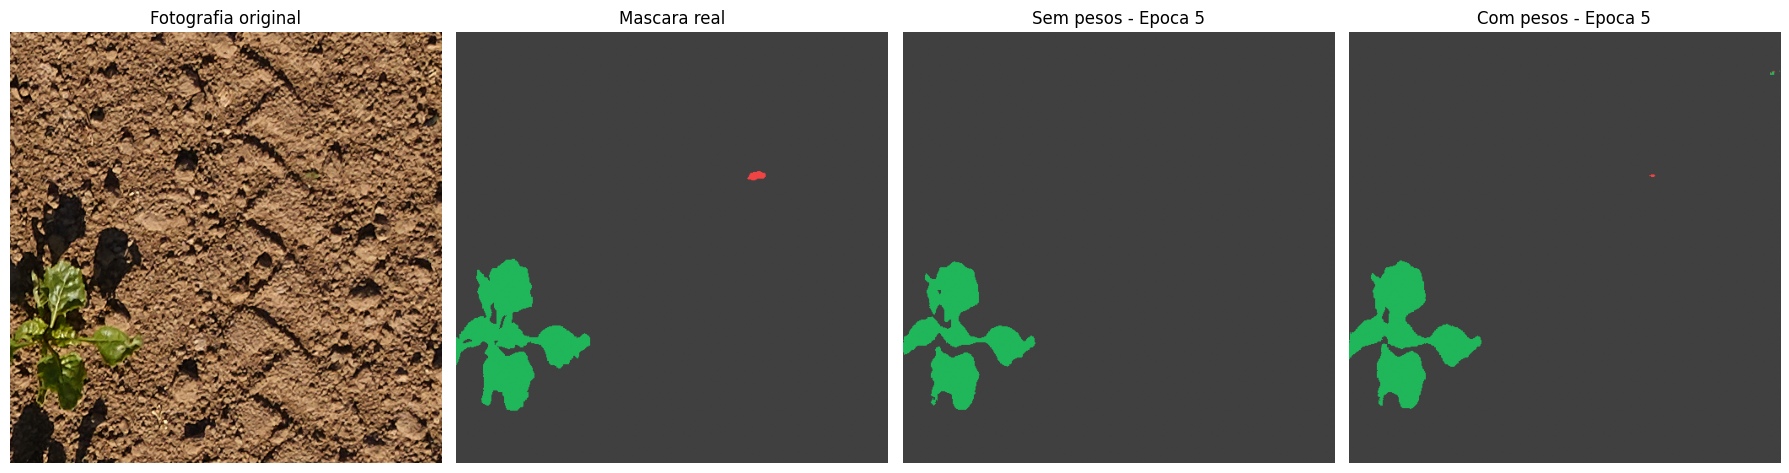


RESULTADOS DO RECORTE

Sem pesos
Pixels previstos: 0
Pixels corretos: 0
IoU das daninhas: 0.0000

Com pesos
Pixels previstos: 19
Pixels corretos: 15
IoU das daninhas: 0.0882

Figura salva em: /content/drive/MyDrive/AgroSeletivo/resultados/comparacao_visual_piloto_epoca5.png


In [16]:

import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

from matplotlib.colors import ListedColormap

sys.path.insert(0, "/content/AgroSeletivo/src")

from dataset_agroseletivo import PhenoBenchDataset


# ==========================================
# 1. CONFIGURACOES
# ==========================================

dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

pasta_modelos = Path(
    "/content/drive/MyDrive/AgroSeletivo/modelos"
)

pasta_resultados = Path(
    "/content/drive/MyDrive/AgroSeletivo/resultados"
)


# ==========================================
# 2. CARREGAR OS MODELOS TREINADOS
# ==========================================

def carregar_modelo(nome_arquivo):

    modelo = smp.Unet(
        encoder_name="mobilenet_v2",
        encoder_weights=None,
        in_channels=3,
        classes=3,
        activation=None
    )

    checkpoint = torch.load(
        pasta_modelos / nome_arquivo,
        map_location="cpu",
        weights_only=True
    )

    modelo.load_state_dict(checkpoint["modelo"])

    modelo = modelo.to(dispositivo)
    modelo.eval()

    return modelo


modelo_sem_pesos = carregar_modelo(
    "unet_piloto_epoca5.pt"
)

modelo_com_pesos = carregar_modelo(
    "unet_pesos_epoca5.pt"
)

print("Dois modelos carregados com sucesso!")


# ==========================================
# 3. SELECIONAR O MESMO RECORTE
# ==========================================

dataset = PhenoBenchDataset("val")

indice = None

for i in range(len(dataset)):

    imagem, mascara = dataset[i]

    if int((mascara == 2).sum()) >= 100:
        indice = i
        break

if indice is None:
    raise ValueError("Nenhum recorte adequado encontrado.")

imagem, mascara = dataset[indice]

print("Recorte de validacao:", indice)


# ==========================================
# 4. EXECUTAR AS DUAS PREVISOES
# ==========================================

entrada = imagem.unsqueeze(0).to(dispositivo)

with torch.inference_mode():

    saida_a = modelo_sem_pesos(entrada)
    saida_b = modelo_com_pesos(entrada)

    previsao_a = torch.argmax(
        saida_a, dim=1
    )[0].cpu().numpy()

    previsao_b = torch.argmax(
        saida_b, dim=1
    )[0].cpu().numpy()

mascara_real = mascara.numpy()


# ==========================================
# 5. RECUPERAR A FOTOGRAFIA
# ==========================================

media = np.array([0.485, 0.456, 0.406])
desvio = np.array([0.229, 0.224, 0.225])

fotografia = imagem.permute(1, 2, 0).numpy()
fotografia = fotografia * desvio + media
fotografia = np.clip(fotografia, 0, 1)


# ==========================================
# 6. COMPARAR VISUALMENTE
# ==========================================

cores = ListedColormap([
    "#404040",
    "#20B65A",
    "#F04444"
])

fig, eixos = plt.subplots(
    1, 4, figsize=(18, 5)
)

eixos[0].imshow(fotografia)
eixos[0].set_title("Fotografia original")

titulos = [
    "Mascara real",
    "Sem pesos - Epoca 5",
    "Com pesos - Epoca 5"
]

mascaras = [
    mascara_real,
    previsao_a,
    previsao_b
]

for i, (titulo, dados) in enumerate(
    zip(titulos, mascaras), start=1
):
    eixos[i].imshow(
        dados,
        cmap=cores,
        vmin=0,
        vmax=2
    )

    eixos[i].set_title(titulo)

for eixo in eixos:
    eixo.axis("off")

plt.tight_layout()

caminho_figura = (
    pasta_resultados /
    "comparacao_visual_piloto_epoca5.png"
)

fig.savefig(
    caminho_figura,
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 7. COMPARAR ACERTOS DAS DANINHAS
# ==========================================

print("\nRESULTADOS DO RECORTE")

real = mascara_real == 2

for nome, prevista in [
    ("Sem pesos", previsao_a),
    ("Com pesos", previsao_b)
]:

    pred = prevista == 2

    corretos = np.count_nonzero(real & pred)
    uniao = np.count_nonzero(real | pred)

    iou = corretos / uniao if uniao else 0.0

    print(f"\n{nome}")
    print("Pixels previstos:", np.count_nonzero(pred))
    print("Pixels corretos:", corretos)
    print(f"IoU das daninhas: {iou:.4f}")

print("\nFigura salva em:", caminho_figura)



## 7. Treinamento com o conjunto completo do PhenoBench

Nesta etapa, treinamos a U-Net com encoder MobileNetV2 utilizando todas as 1.407 fotografias disponíveis no conjunto oficial de treinamento.

### 7.1 — Experimento com Cross-Entropy ponderada

**Objetivo:** investigar se a utilização de mais exemplos melhora a segmentação de plantas daninhas.

**Configurações:**
- 1.407 fotografias de treinamento.
- 50 fotografias de validação provisória.
- Recortes de 512 × 512 pixels.
- U-Net com encoder MobileNetV2 pré-treinado.
- Cross-Entropy com pesos para as três classes.
- Otimizador AdamW.
- Taxa de aprendizado de 0,0001.
- Lotes de 2 imagens.
- 5 épocas iniciais.

O treinamento começará com uma nova rede, sem utilizar os pesos ajustados durante o experimento piloto.

**Avaliação:** serão calculadas IoU, precisão e recall de cada classe após cada época.

O melhor checkpoint será selecionado pela IoU das plantas daninhas no conjunto de validação.

Os resultados serão salvos no Google Drive para permitir comparações posteriores.

**Limitação:** a validação deste experimento já foi utilizada em análises anteriores. Portanto, não será considerada uma avaliação final independente.


In [18]:

import sys
import json
import random
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import DataLoader

# ==========================================
# 1. CONFIGURACOES
# ==========================================

sys.path.insert(0, "/content/AgroSeletivo/src")

from dataset_agroseletivo import PhenoBenchDataset
from modelo_agroseletivo import criar_modelo

SEMENTE = 42
EPOCAS = 5
BATCH_SIZE = 2
TAXA_APRENDIZADO = 0.0001

random.seed(SEMENTE)
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
torch.cuda.manual_seed_all(SEMENTE)

if not torch.cuda.is_available():
    raise RuntimeError("GPU CUDA nao disponivel.")

dispositivo = torch.device("cuda")

DRIVE = Path("/content/drive/MyDrive/AgroSeletivo")
PASTA_MODELOS = DRIVE / "modelos"
PASTA_RESULTADOS = DRIVE / "resultados"

PASTA_MODELOS.mkdir(parents=True, exist_ok=True)
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

print("AGROSELETIVO - TREINAMENTO COMPLETO")
print("GPU:", torch.cuda.get_device_name(0))


# ==========================================
# 2. CARREGAR OS DADOS
# ==========================================

treino = PhenoBenchDataset("train")
validacao = PhenoBenchDataset("val")

assert len(treino.arquivos) == 1407
assert len(validacao.arquivos) == 50

carregador_treino = DataLoader(
    treino,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

carregador_val = DataLoader(
    validacao,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\nFotografias de treino:", len(treino.arquivos))
print("Fotografias de validacao:", len(validacao.arquivos))
print("Lotes de treinamento:", len(carregador_treino))


# ==========================================
# 3. CRIAR O MODELO
# ==========================================

# Criar uma nova U-Net com encoder
# pre-treinado em ImageNet
modelo_completo = criar_modelo().to(dispositivo)

# Frequencias calculadas no conjunto
# completo de treinamento
frequencias = torch.tensor(
    [0.87657, 0.11846, 0.00497],
    dtype=torch.float32,
    device=dispositivo
)

pesos = torch.sqrt(
    frequencias[0] / frequencias
)

criterio_treino = torch.nn.CrossEntropyLoss(
    weight=pesos
)

# Perda sem pesos para acompanhar a validacao
criterio_val = torch.nn.CrossEntropyLoss()

otimizador = torch.optim.AdamW(
    modelo_completo.parameters(),
    lr=TAXA_APRENDIZADO
)

print("\nPesos das classes:", pesos.tolist())


# ==========================================
# 4. PREPARAR O HISTORICO
# ==========================================

historico = []
melhor_iou = -1.0

caminho_melhor = (
    PASTA_MODELOS / "unet_completo_ponderado_melhor.pt"
)

caminho_ultimo = (
    PASTA_MODELOS / "unet_completo_ponderado_ultimo.pt"
)

caminho_historico = (
    PASTA_RESULTADOS /
    "historico_completo_ponderado.json"
)


# ==========================================
# 5. TREINAMENTO
# ==========================================

for epoca in range(1, EPOCAS + 1):

    print(f"\n========== EPOCA {epoca}/{EPOCAS} ==========")

    modelo_completo.train()
    soma_treino = 0.0

    for numero, (imagens, mascaras) in enumerate(
        carregador_treino, start=1
    ):

        imagens = imagens.to(dispositivo)
        mascaras = mascaras.to(dispositivo)

        otimizador.zero_grad(set_to_none=True)

        saida = modelo_completo(imagens)
        perda = criterio_treino(saida, mascaras)

        if not torch.isfinite(perda).item():
            raise ValueError("Perda de treinamento invalida.")

        perda.backward()
        otimizador.step()

        soma_treino += perda.item() * imagens.size(0)

        if numero % 100 == 0:
            print(
                f"Lote {numero}/{len(carregador_treino)}"
                f" - Perda: {perda.item():.4f}"
            )

    perda_treino = soma_treino / len(treino)


    # ======================================
    # 6. VALIDACAO
    # ======================================

    modelo_completo.eval()
    soma_val = 0.0

    matriz = torch.zeros(
        (3, 3),
        dtype=torch.int64,
        device=dispositivo
    )

    with torch.inference_mode():

        for imagens, mascaras in carregador_val:

            imagens = imagens.to(dispositivo)
            mascaras = mascaras.to(dispositivo)

            saida = modelo_completo(imagens)

            perda = criterio_val(saida, mascaras)

            soma_val += perda.item() * imagens.size(0)

            previsoes = torch.argmax(saida, dim=1)

            indices = (
                mascaras.reshape(-1) * 3
                + previsoes.reshape(-1)
            )

            matriz += torch.bincount(
                indices,
                minlength=9
            ).reshape(3, 3)

    perda_val = soma_val / len(validacao)

    matriz_cpu = matriz.cpu().numpy()


    # ======================================
    # 7. CALCULAR AS METRICAS
    # ======================================

    metricas = {}

    nomes = ["Solo", "Cultura", "Daninhas"]

    print(f"\nPerda treino ponderada: {perda_treino:.4f}")
    print(f"Perda validacao sem pesos: {perda_val:.4f}")

    for classe, nome in enumerate(nomes):

        vp = matriz_cpu[classe, classe]

        reais = matriz_cpu[classe, :].sum()
        previstos = matriz_cpu[:, classe].sum()

        uniao = reais + previstos - vp

        iou = vp / uniao if uniao > 0 else 0.0

        precisao = (
            vp / previstos if previstos > 0 else 0.0
        )

        recall = (
            vp / reais if reais > 0 else 0.0
        )

        metricas[nome] = {
            "iou": float(iou),
            "precisao": float(precisao),
            "recall": float(recall)
        }

        print(
            f"{nome}: IoU={iou:.4f}, "
            f"Precisao={precisao:.4f}, "
            f"Recall={recall:.4f}"
        )


    # ======================================
    # 8. REGISTRAR O EXPERIMENTO
    # ======================================

    registro = {
        "epoca": epoca,
        "perda_treino_ponderada": perda_treino,
        "perda_validacao_sem_pesos": perda_val,
        "metricas": metricas,
        "matriz_confusao": matriz_cpu.tolist()
    }

    historico.append(registro)

    # Guardar o estado para permitir continuidade
    checkpoint = {
        "epoca": epoca,
        "modelo": modelo_completo.state_dict(),
        "otimizador": otimizador.state_dict(),
        "metricas": metricas,
        "pesos_classes": pesos.cpu()
    }

    # Salvar a ultima epoca
    torch.save(checkpoint, caminho_ultimo)

    # Salvar separadamente o melhor modelo
    iou_daninhas = metricas["Daninhas"]["iou"]

    if iou_daninhas > melhor_iou:

        melhor_iou = iou_daninhas

        torch.save(checkpoint, caminho_melhor)

        print(
            f"Novo melhor modelo! "
            f"IoU daninhas: {melhor_iou:.4f}"
        )

    # Preservar as metricas de cada epoca
    with open(caminho_historico, "w") as arquivo:
        json.dump(historico, arquivo, indent=4)

    print(f"Epoca {epoca} salva com sucesso!")


# ==========================================
# 9. RESULTADO FINAL
# ==========================================

print("\nTREINAMENTO COMPLETO FINALIZADO!")

print("Melhor IoU das daninhas:", round(melhor_iou, 4))

print("Melhor modelo:", caminho_melhor)
print("Ultimo checkpoint:", caminho_ultimo)
print("Historico:", caminho_historico)


AGROSELETIVO - TREINAMENTO COMPLETO
GPU: Tesla T4

Fotografias de treino: 1407
Fotografias de validacao: 50
Lotes de treinamento: 704

Pesos das classes: [1.0, 2.7202413082122803, 13.28052043914795]

========== EPOCA 1/5 ==========
Lote 100/704 - Perda: 0.3380
Lote 200/704 - Perda: 0.3611
Lote 300/704 - Perda: 0.1873
Lote 400/704 - Perda: 0.1308
Lote 500/704 - Perda: 0.1278
Lote 600/704 - Perda: 0.0802
Lote 700/704 - Perda: 0.1032

Perda treino ponderada: 0.2780
Perda validacao sem pesos: 0.0480
Solo: IoU=0.9904, Precisao=0.9966, Recall=0.9937
Cultura: IoU=0.9105, Precisao=0.9547, Recall=0.9516
Daninhas: IoU=0.4669, Precisao=0.5276, Recall=0.8023
Novo melhor modelo! IoU daninhas: 0.4669
Epoca 1 salva com sucesso!

========== EPOCA 2/5 ==========
Lote 100/704 - Perda: 0.0642
Lote 200/704 - Perda: 0.0563
Lote 300/704 - Perda: 0.0505
Lote 400/704 - Perda: 0.0756
Lote 500/704 - Perda: 0.0569
Lote 600/704 - Perda: 0.0414
Lote 700/704 - Perda: 0.0524

Perda treino ponderada: 0.0995
Perda val


## 8. Avaliação do modelo em imagens reservadas

Nesta etapa, avaliamos o melhor modelo do AgroSeletivo em fotografias que não foram utilizadas durante a seleção dos modelos e de seus parâmetros.

O conjunto reservado contém:

- 722 fotografias do PhenoBench.
- 722 máscaras de segmentação correspondentes.
- Nenhuma das 50 fotografias utilizadas na validação dos experimentos anteriores.

**Objetivo:** verificar se o desempenho observado durante o desenvolvimento se mantém em um conjunto maior de fotografias.

O modelo avaliado será a U-Net com MobileNetV2 e Cross-Entropy ponderada, selecionada na época 3 do treinamento completo.

Durante a avaliação, os pesos da rede neural não serão modificados.

**Limitação:** as imagens pertencem ao mesmo dataset e podem compartilhar características ou sessões de captura. Portanto, esta avaliação não comprova, isoladamente, a generalização para outras lavouras.

### 8.1 — Carregamento das imagens reservadas

Nesta etapa, extraímos o conjunto de avaliação do Google Drive para o armazenamento temporário do Colab.

Os arquivos serão mantidos em uma pasta separada dos conjuntos de treinamento e validação usados anteriormente.

Antes de executar a avaliação, verificaremos a quantidade de fotografias e máscaras e a correspondência entre seus nomes.


In [19]:

from pathlib import Path
from zipfile import ZipFile
import shutil

# ==========================================
# 1. DEFINIR OS CAMINHOS
# ==========================================

DRIVE = Path("/content/drive/MyDrive/AgroSeletivo")

arquivo_zip = (
    DRIVE / "dados" / "AgroSeletivo_avaliacao_722.zip"
)

zip_local = Path(
    "/content/AgroSeletivo_avaliacao_722.zip"
)

pasta_dados = Path(
    "/content/AgroSeletivo/dados"
)

pasta_avaliacao = pasta_dados / "avaliacao"

print("AGROSELETIVO - PREPARACAO DA AVALIACAO")


# ==========================================
# 2. CONFERIR O PACOTE
# ==========================================

if not arquivo_zip.is_file():
    raise FileNotFoundError(
        f"Pacote nao encontrado: {arquivo_zip}"
    )

with ZipFile(arquivo_zip, "r") as pacote:

    nomes = pacote.namelist()

    imagens_zip = {
        Path(nome).name
        for nome in nomes
        if nome.startswith("avaliacao/imagens/")
        and nome.endswith(".png")
    }

    mascaras_zip = {
        Path(nome).name
        for nome in nomes
        if nome.startswith("avaliacao/mascaras/")
        and nome.endswith(".png")
    }

    nomes_esperados = (
        {"avaliacao/arquivos_reservados.txt"}
        | {f"avaliacao/imagens/{n}" for n in imagens_zip}
        | {f"avaliacao/mascaras/{n}" for n in mascaras_zip}
    )

    if set(nomes) != nomes_esperados:
        raise ValueError("Estrutura inesperada no ZIP.")

    if len(nomes) != 1445:
        raise ValueError("Quantidade inesperada de arquivos.")

    if len(imagens_zip) != 722:
        raise ValueError("Quantidade de imagens incorreta.")

    if imagens_zip != mascaras_zip:
        raise ValueError("Imagens e mascaras nao correspondem.")

print("Pacote verificado com sucesso!")


# ==========================================
# 3. EXTRAIR PARA O COLAB
# ==========================================

print("\nPreparando extracao...")

with ZipFile(arquivo_zip, "r") as pacote:

    tamanho_extraido = sum(
        item.file_size for item in pacote.infolist()
    )

espaco_livre = shutil.disk_usage("/content").free

espaco_necessario = (
    arquivo_zip.stat().st_size
    + tamanho_extraido
    + 512 * 1024**2
)

if espaco_livre < espaco_necessario:
    raise RuntimeError(
        "Espaco insuficiente no Colab."
    )

shutil.copy2(arquivo_zip, zip_local)

try:

    with ZipFile(zip_local, "r") as pacote:
        pacote.extractall(pasta_dados)

finally:

    # Remove somente a copia temporaria do ZIP
    zip_local.unlink(missing_ok=True)

print("Extracao finalizada!")


# ==========================================
# 4. CONFERIR AS FOTOGRAFIAS
# ==========================================

imagens = sorted(
    (pasta_avaliacao / "imagens").glob("*.png")
)

mascaras = sorted(
    (pasta_avaliacao / "mascaras").glob("*.png")
)

nomes_imagens = {a.name for a in imagens}
nomes_mascaras = {a.name for a in mascaras}

assert len(imagens) == 722
assert len(mascaras) == 722
assert nomes_imagens == nomes_mascaras

print("\nCONJUNTO RESERVADO")
print("Fotografias:", len(imagens))
print("Mascaras:", len(mascaras))
print("Correspondencia:", nomes_imagens == nomes_mascaras)


# ==========================================
# 5. VERIFICAR SEPARACAO DO PILOTO
# ==========================================

arquivo_piloto = (
    DRIVE / "dados" / "AgroSeletivo_dados_piloto.zip"
)

with ZipFile(arquivo_piloto, "r") as pacote:

    manifesto = pacote.read(
        "val/arquivos_selecionados.txt"
    ).decode("utf-8")

nomes_piloto = {
    nome.strip()
    for nome in manifesto.splitlines()
    if nome.strip()
}

repetidas = nomes_imagens & nomes_piloto

print("\nVERIFICACAO DA SEPARACAO")
print("Imagens repetidas do piloto:", len(repetidas))

assert len(nomes_piloto) == 50
assert len(repetidas) == 0

print("\nDados reservados preparados com sucesso!")


AGROSELETIVO - PREPARACAO DA AVALIACAO
Pacote verificado com sucesso!

Preparando extracao...
Extracao finalizada!

CONJUNTO RESERVADO
Fotografias: 722
Mascaras: 722
Correspondencia: True


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/AgroSeletivo/dados/AgroSeletivo_dados_piloto.zip'


### 8.1.1 — Verificação da separação dos conjuntos

Nesta etapa, verificamos se as 722 fotografias reservadas para avaliação são diferentes das 50 fotografias utilizadas durante o desenvolvimento.

A comparação utiliza os nomes dos arquivos já extraídos no Colab, sem depender do ZIP original do conjunto piloto.

**Objetivo:** confirmar que nenhuma fotografia utilizada na validação do piloto foi incluída novamente no conjunto reservado.


In [20]:

from pathlib import Path

# ==========================================
# 1. LOCALIZAR OS CONJUNTOS
# ==========================================

base = Path("/content/AgroSeletivo/dados")

pasta_piloto = base / "phenobench" / "val" / "imagens"
pasta_reservada = base / "avaliacao" / "imagens"


# ==========================================
# 2. LISTAR AS FOTOGRAFIAS
# ==========================================

nomes_piloto = {
    arquivo.name
    for arquivo in pasta_piloto.glob("*.png")
}

nomes_reservados = {
    arquivo.name
    for arquivo in pasta_reservada.glob("*.png")
}


# ==========================================
# 3. VERIFICAR A SEPARACAO
# ==========================================

repetidas = nomes_piloto & nomes_reservados

print("AGROSELETIVO - VERIFICACAO DA AVALIACAO")

print("\nFotografias do piloto:", len(nomes_piloto))
print("Fotografias reservadas:", len(nomes_reservados))
print("Nomes repetidos:", len(repetidas))

assert len(nomes_piloto) == 50
assert len(nomes_reservados) == 722
assert len(repetidas) == 0

print("\nSeparacao dos conjuntos confirmada!")


AGROSELETIVO - VERIFICACAO DA AVALIACAO

Fotografias do piloto: 50
Fotografias reservadas: 722
Nomes repetidos: 0

Separacao dos conjuntos confirmada!


### 8.2 — Avaliação quantitativa do melhor modelo

Nesta etapa, avaliamos o desempenho da U-Net em 722 fotografias reservadas do PhenoBench.

**Modelo avaliado:**
- Arquitetura U-Net com encoder MobileNetV2.
- Treinamento com 1.407 fotografias.
- Função Cross-Entropy ponderada.
- Checkpoint selecionado na época 3.

**Procedimento:**

Cada fotografia de 1024 × 1024 pixels será dividida em quatro recortes fixos de 512 × 512 pixels.

A rede produzirá uma máscara prevista para cada recorte, que será comparada com a máscara real fornecida pelo PhenoBench.

**Métricas calculadas:**
- IoU por classe.
- Precisão por classe.
- Recall por classe.
- Matriz de confusão.
- Perda média de avaliação.

Os pesos da rede permanecerão congelados durante toda a avaliação.

**Objetivo:** verificar se o desempenho observado nas 50 fotografias de desenvolvimento se mantém nas 722 fotografias reservadas.

**Limitação:** a separação por nomes foi confirmada, mas ainda não verificamos possíveis semelhanças entre sessões de captura. Portanto, os resultados não demonstram, isoladamente, generalização para novas lavouras.

In [21]:

import sys
import json
from pathlib import Path

import torch
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader

# ==========================================
# 1. CONFIGURAR OS CAMINHOS
# ==========================================

sys.path.insert(0, "/content/AgroSeletivo/src")

from dataset_agroseletivo import PhenoBenchDataset

RAIZ = Path("/content/AgroSeletivo")

DRIVE = Path(
    "/content/drive/MyDrive/AgroSeletivo"
)

PASTA_AVALIACAO = RAIZ / "dados" / "avaliacao"

CAMINHO_MODELO = (
    DRIVE / "modelos" /
    "unet_completo_ponderado_melhor.pt"
)

CAMINHO_RESULTADOS = (
    DRIVE / "resultados" /
    "avaliacao_reservada_722.json"
)

dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("AGROSELETIVO - AVALIACAO RESERVADA")


# ==========================================
# 2. PREPARAR OS DADOS
# ==========================================

# Reutilizar o processamento fixo da validacao
dataset = PhenoBenchDataset("val")

# Direcionar para as 722 imagens reservadas
dataset.pasta_imagens = (
    PASTA_AVALIACAO / "imagens"
)

dataset.pasta_mascaras = (
    PASTA_AVALIACAO / "mascaras"
)

dataset.arquivos = sorted(
    dataset.pasta_imagens.glob("*.png")
)

assert len(dataset.arquivos) == 722

carregador = DataLoader(
    dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0
)

print("\nDADOS")
print("Fotografias:", len(dataset.arquivos))
print("Recortes:", len(dataset))
print("Lotes:", len(carregador))


# ==========================================
# 3. CARREGAR O MELHOR MODELO
# ==========================================

checkpoint = torch.load(
    CAMINHO_MODELO,
    map_location="cpu",
    weights_only=True
)

modelo_avaliacao = smp.Unet(
    encoder_name="mobilenet_v2",
    encoder_weights=None,
    in_channels=3,
    classes=3,
    activation=None
)

modelo_avaliacao.load_state_dict(
    checkpoint["modelo"]
)

modelo_avaliacao = modelo_avaliacao.to(dispositivo)

# Ativar modo de avaliacao
modelo_avaliacao.eval()

print("\nMODELO")
print("Checkpoint:", CAMINHO_MODELO.name)
print("Epoca:", checkpoint["epoca"])
print("Dispositivo:", dispositivo)


# ==========================================
# 4. PREPARAR AS METRICAS
# ==========================================

criterio = torch.nn.CrossEntropyLoss()

matriz = torch.zeros(
    (3, 3),
    dtype=torch.int64,
    device=dispositivo
)

soma_perda = 0.0
recortes_processados = 0


# ==========================================
# 5. EXECUTAR A AVALIACAO
# ==========================================

print("\nIniciando avaliacao...")

with torch.inference_mode():

    for numero, (imagens, mascaras) in enumerate(
        carregador, start=1
    ):

        imagens = imagens.to(dispositivo)
        mascaras = mascaras.to(dispositivo)

        # Gerar previsoes
        saida = modelo_avaliacao(imagens)

        # Calcular perda sem pesos
        perda = criterio(saida, mascaras)

        soma_perda += (
            perda.item() * imagens.size(0)
        )

        recortes_processados += imagens.size(0)

        # Selecionar a classe prevista
        previsoes = torch.argmax(
            saida, dim=1
        )

        # Atualizar a matriz de confusao
        indices = (
            mascaras.reshape(-1) * 3
            + previsoes.reshape(-1)
        )

        matriz += torch.bincount(
            indices,
            minlength=9
        ).reshape(3, 3)

        # Mostrar o progresso
        if numero % 200 == 0 or numero == len(carregador):
            print(
                f"Lotes avaliados: "
                f"{numero}/{len(carregador)}"
            )


# ==========================================
# 6. CALCULAR OS RESULTADOS
# ==========================================

matriz_cpu = matriz.cpu().numpy()

perda_media = (
    soma_perda / recortes_processados
)

nomes = ["Solo", "Cultura", "Daninhas"]

metricas = {}

print("\nRESULTADOS DA AVALIACAO")
print(f"Perda media: {perda_media:.4f}")

for classe, nome in enumerate(nomes):

    vp = matriz_cpu[classe, classe]

    reais = matriz_cpu[classe, :].sum()
    previstos = matriz_cpu[:, classe].sum()

    uniao = reais + previstos - vp

    iou = vp / uniao if uniao > 0 else 0.0

    precisao = (
        vp / previstos if previstos > 0 else 0.0
    )

    recall = (
        vp / reais if reais > 0 else 0.0
    )

    metricas[nome] = {
        "iou": float(iou),
        "precisao": float(precisao),
        "recall": float(recall)
    }

    print(
        f"{nome}: "
        f"IoU={iou:.4f}, "
        f"Precisao={precisao:.4f}, "
        f"Recall={recall:.4f}"
    )


# ==========================================
# 7. MOSTRAR A MATRIZ DE CONFUSAO
# ==========================================

print("\nMATRIZ DE CONFUSAO")
print("Linhas: classe real")
print("Colunas: classe prevista")

print(matriz_cpu)


# ==========================================
# 8. SALVAR OS RESULTADOS
# ==========================================

resultado_final = {
    "modelo": CAMINHO_MODELO.name,
    "epoca": int(checkpoint["epoca"]),
    "fotografias": len(dataset.arquivos),
    "recortes": recortes_processados,
    "perda_media": float(perda_media),
    "metricas": metricas,
    "matriz_confusao": matriz_cpu.tolist()
}

CAMINHO_RESULTADOS.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(CAMINHO_RESULTADOS, "w") as arquivo:
    json.dump(
        resultado_final,
        arquivo,
        indent=4
    )

print("\nAVALIACAO FINALIZADA!")
print("Resultados salvos em:", CAMINHO_RESULTADOS)


AGROSELETIVO - AVALIACAO RESERVADA

DADOS
Fotografias: 722
Recortes: 2888
Lotes: 1444

MODELO
Checkpoint: unet_completo_ponderado_melhor.pt
Epoca: 3
Dispositivo: cuda

Iniciando avaliacao...
Lotes avaliados: 200/1444
Lotes avaliados: 400/1444
Lotes avaliados: 600/1444
Lotes avaliados: 800/1444
Lotes avaliados: 1000/1444
Lotes avaliados: 1200/1444
Lotes avaliados: 1400/1444
Lotes avaliados: 1444/1444

RESULTADOS DA AVALIACAO
Perda media: 0.0292
Solo: IoU=0.9909, Precisao=0.9983, Recall=0.9925
Cultura: IoU=0.9310, Precisao=0.9465, Recall=0.9827
Daninhas: IoU=0.5532, Precisao=0.6309, Recall=0.8178

MATRIZ DE CONFUSAO
Linhas: classe real
Colunas: classe prevista
[[675312386   3625137   1457937]
 [   812549  71437908    446046]
 [   314716    410503   3254690]]

AVALIACAO FINALIZADA!
Resultados salvos em: /content/drive/MyDrive/AgroSeletivo/resultados/avaliacao_reservada_722.json



### 8.3 — Comparação dos resultados de desenvolvimento e avaliação reservada

Nesta etapa, comparamos o desempenho do melhor modelo nos dois conjuntos de fotografias do PhenoBench.

- **Desenvolvimento:** 50 fotografias utilizadas para selecionar o modelo.
- **Avaliação reservada:** 722 fotografias que não participaram dessa seleção.

A comparação considera a IoU das classes solo, cultura e plantas daninhas.

**Objetivo:** verificar a estabilidade das métricas entre os conjuntos e produzir um gráfico para a documentação do AgroSeletivo.

Os resultados são específicos do PhenoBench e não garantem o mesmo desempenho em outras lavouras.


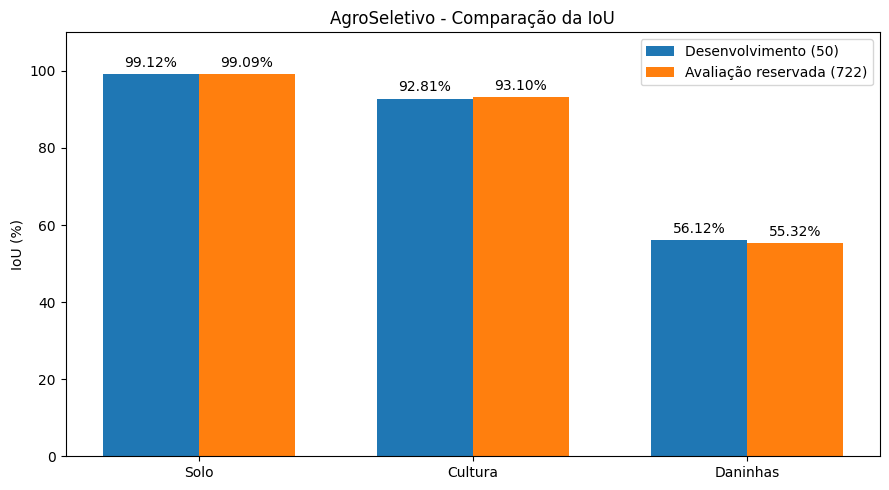

Melhor época: 3
Gráfico salvo em: /content/drive/MyDrive/AgroSeletivo/resultados/comparacao_iou_avaliacao.png


In [22]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# 1. Localizar os resultados salvos
pasta = Path(
    "/content/drive/MyDrive/AgroSeletivo/resultados"
)

with open(pasta / "historico_completo_ponderado.json") as f:
    historico = json.load(f)

with open(pasta / "avaliacao_reservada_722.json") as f:
    avaliacao = json.load(f)

# 2. Selecionar a melhor epoca do desenvolvimento
melhor = max(
    historico,
    key=lambda r: r["metricas"]["Daninhas"]["iou"]
)

classes = ["Solo", "Cultura", "Daninhas"]

iou_dev = [
    melhor["metricas"][classe]["iou"] * 100
    for classe in classes
]

iou_reservada = [
    avaliacao["metricas"][classe]["iou"] * 100
    for classe in classes
]

# 3. Construir o grafico
posicoes = np.arange(len(classes))
largura = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

barras_dev = ax.bar(
    posicoes - largura / 2,
    iou_dev,
    largura,
    label="Desenvolvimento (50)"
)

barras_res = ax.bar(
    posicoes + largura / 2,
    iou_reservada,
    largura,
    label="Avaliação reservada (722)"
)

ax.bar_label(barras_dev, fmt="%.2f%%", padding=3)
ax.bar_label(barras_res, fmt="%.2f%%", padding=3)

ax.set_xticks(posicoes, classes)
ax.set_ylabel("IoU (%)")
ax.set_ylim(0, 110)
ax.set_title("AgroSeletivo - Comparação da IoU")
ax.legend()

plt.tight_layout()

# 4. Salvar no Google Drive
saida = pasta / "comparacao_iou_avaliacao.png"

fig.savefig(saida, dpi=180, bbox_inches="tight")
plt.show()

print("Melhor época:", melhor["epoca"])
print("Gráfico salvo em:", saida)



### 8.4 — Análise visual de fotografias reservadas

Nesta etapa, avaliamos visualmente a segmentação produzida pelo melhor modelo do AgroSeletivo.

Três fotografias são selecionadas aleatoriamente, utilizando uma semente fixa para permitir a reprodução da análise.

Para cada fotografia, apresentamos:

- Fotografia original.
- Máscara real fornecida pelo PhenoBench.
- Máscara prevista pela U-Net.
- Sobreposição da previsão sobre a fotografia.

As imagens de 1024 × 1024 pixels são processadas em quatro recortes de 512 × 512 e reconstruídas na resolução original.

**Objetivo:** observar a localização das plantas, identificar erros de segmentação e produzir exemplos visuais para a apresentação.

Não haverá treinamento nem modificação dos parâmetros da rede. Essas imagens não serão utilizadas para escolher uma nova configuração do modelo.


In [23]:

import random
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp

from PIL import Image
from matplotlib.colors import ListedColormap


# ==========================================
# 1. CONFIGURAR CAMINHOS E DISPOSITIVO
# ==========================================

RAIZ = Path("/content/AgroSeletivo")

DRIVE = Path("/content/drive/MyDrive/AgroSeletivo")

PASTA_IMAGENS = RAIZ / "dados/avaliacao/imagens"
PASTA_MASCARAS = RAIZ / "dados/avaliacao/mascaras"

PASTA_SAIDA = DRIVE / "resultados/visualizacoes_reservadas"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

CAMINHO_MODELO = (
    DRIVE / "modelos/unet_completo_ponderado_melhor.pt"
)

dispositivo = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ==========================================
# 2. CARREGAR O MELHOR MODELO
# ==========================================

modelo_visual = smp.Unet(
    encoder_name="mobilenet_v2",
    encoder_weights=None,
    in_channels=3,
    classes=3,
    activation=None
)

checkpoint = torch.load(
    CAMINHO_MODELO,
    map_location="cpu",
    weights_only=True
)

modelo_visual.load_state_dict(checkpoint["modelo"])
modelo_visual = modelo_visual.to(dispositivo)
modelo_visual.eval()

print("Modelo carregado!")
print("Epoca:", checkpoint["epoca"])


# ==========================================
# 3. SELECIONAR TRES FOTOGRAFIAS
# ==========================================

arquivos = sorted(PASTA_IMAGENS.glob("*.png"))

assert len(arquivos) == 722

gerador = random.Random(42)

selecionadas = gerador.sample(arquivos, 3)

print("\nFotografias selecionadas:")

for arquivo in selecionadas:
    print("-", arquivo.name)


# ==========================================
# 4. PREPARAR NORMALIZACAO E CORES
# ==========================================

media = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

desvio = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

paleta = np.array([
    [64, 64, 64],    # Solo
    [32, 182, 90],   # Cultura
    [240, 68, 68]    # Daninhas
], dtype=np.uint8)

cores = ListedColormap(paleta / 255.0)


# ==========================================
# 5. FUNCOES AUXILIARES
# ==========================================

def sobrepor(foto, mascara):
    resultado = foto.copy()

    plantas = mascara > 0

    resultado[plantas] = (
        0.55 * foto[plantas]
        + 0.45 * paleta[mascara[plantas]]
    ).astype(np.uint8)

    return resultado


def prever_fotografia(foto):
    previsao = np.zeros((1024, 1024), dtype=np.uint8)

    with torch.inference_mode():

        for y in (0, 512):
            for x in (0, 512):

                recorte = np.ascontiguousarray(
                    foto[y:y+512, x:x+512]
                )

                tensor = torch.from_numpy(recorte)
                tensor = tensor.permute(2, 0, 1).float()
                tensor = tensor / 255.0

                tensor = (tensor - media) / desvio

                entrada = tensor.unsqueeze(0).to(dispositivo)

                saida = modelo_visual(entrada)

                pred = torch.argmax(
                    saida, dim=1
                )[0].cpu().numpy()

                previsao[y:y+512, x:x+512] = pred

    return previsao


# ==========================================
# 6. AVALIAR AS TRES FOTOGRAFIAS
# ==========================================

for numero, caminho in enumerate(selecionadas, start=1):

    with Image.open(caminho) as arquivo:
        foto = np.array(arquivo.convert("RGB"))

    with Image.open(PASTA_MASCARAS / caminho.name) as arquivo:
        mascara = np.array(arquivo)

    assert foto.shape == (1024, 1024, 3)
    assert mascara.shape == (1024, 1024)

    # Converter as classes originais
    assert np.isin(mascara, [0, 1, 2, 3, 4]).all()

    mascara = mascara.astype(np.uint8)
    mascara[mascara == 3] = 1
    mascara[mascara == 4] = 2

    previsao = prever_fotografia(foto)

    # Calcular a IoU das daninhas nesta fotografia
    real = mascara == 2
    previsto = previsao == 2

    acertos = np.count_nonzero(real & previsto)
    uniao = np.count_nonzero(real | previsto)

    iou = acertos / uniao if uniao > 0 else None

    # Mostrar quatro visualizacoes
    fig, eixos = plt.subplots(
        1, 4, figsize=(18, 5)
    )

    eixos[0].imshow(foto)
    eixos[0].set_title("Fotografia original")

    eixos[1].imshow(
        mascara, cmap=cores, vmin=0, vmax=2
    )
    eixos[1].set_title("Mascara real")

    eixos[2].imshow(
        previsao, cmap=cores, vmin=0, vmax=2
    )
    eixos[2].set_title("Mascara prevista")

    eixos[3].imshow(
        sobrepor(foto, previsao)
    )
    eixos[3].set_title("Previsao sobre a fotografia")

    for eixo in eixos:
        eixo.axis("off")

    plt.suptitle(
        f"AgroSeletivo - Exemplo {numero}",
        fontsize=14
    )

    plt.tight_layout()

    saida = (
        PASTA_SAIDA / f"exemplo_reservado_{numero}.png"
    )

    fig.savefig(saida, dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print(f"\nEXEMPLO {numero}: {caminho.name}")
    print("Pixels reais de daninhas:", np.count_nonzero(real))
    print("Pixels previstos:", np.count_nonzero(previsto))
    print("Pixels corretos:", acertos)

    if iou is None:
        print("IoU: indefinida (sem pixels reais ou previstos)")
    else:
        print(f"IoU das daninhas: {iou:.4f}")

    print("Figura salva em:", saida)


print("\nAnalise visual concluida!")


Output hidden; open in https://colab.research.google.com to view.